# Example 1 — Data quality: did the TDC record timing?

Run this first on every fresh timestamping acquisition (`ORT`, `S0T`...). When
the ring-oscillator TDC never stops, `unpack` still returns plausible integers
and every other analysis still produces a plot — a meaningless one. The only way
to catch it is to look at the raw TDC codes.

Full explanation: [Data quality](../docs/guide/data_quality.md).

## What you need

- dapkel installed: `pip install dapkel`
- a folder of `.bin` files from a timestamping program, e.g.
  `D:\Kelpie\2026.10.30\` holding `..._ORT_0.bin`, `..._ORT_1.bin`, ...
- the number of frames you acquired per file (`nframes`). The file size does not
  tell you this, so use the number you set for the acquisition.

## 1. Point dapkel at the data

In [1]:
import numpy as np

from dapkel.functions import data_quality

path = r"D:\Kelpie\2026.10.30"
nframes = 10_000
tag = "ORT"
# tag = "S0T"

## 2. Histogram the TDC codes of every pixel

A handful of files is enough to see whether the timing is populated.
`process_time_codes` saves the per-pixel code histogram, shape
`(32, 32, n_codes)`, to `processed/<folder>_ort_time_codes.npy` and returns that
path.

In [2]:
saved = data_quality.process_time_codes(path, nframes, tag, max_files=5)
print(saved)

ORT: 100%|██████████| 5/5 [00:04<00:00,  1.18it/s]


> > > Saved to D:\Kelpie\2026.10.30\processed\2026.10.30_ort_time_codes.npy < < <
D:\Kelpie\2026.10.30\processed\2026.10.30_ort_time_codes.npy


## 3. Look at one pixel

`plot_time_codes` reads the saved histogram (it does not re-read the `.bin`
files), saves the figure to `results/data_quality/` and returns that pixel's
counts per code.


> > > Plot is saved as 2026.10.30_ort_time_codes_5_16.png in D:\Kelpie\2026.10.30\results\data_quality < < <
773 timestamps, 594 unique codes, last code 1341


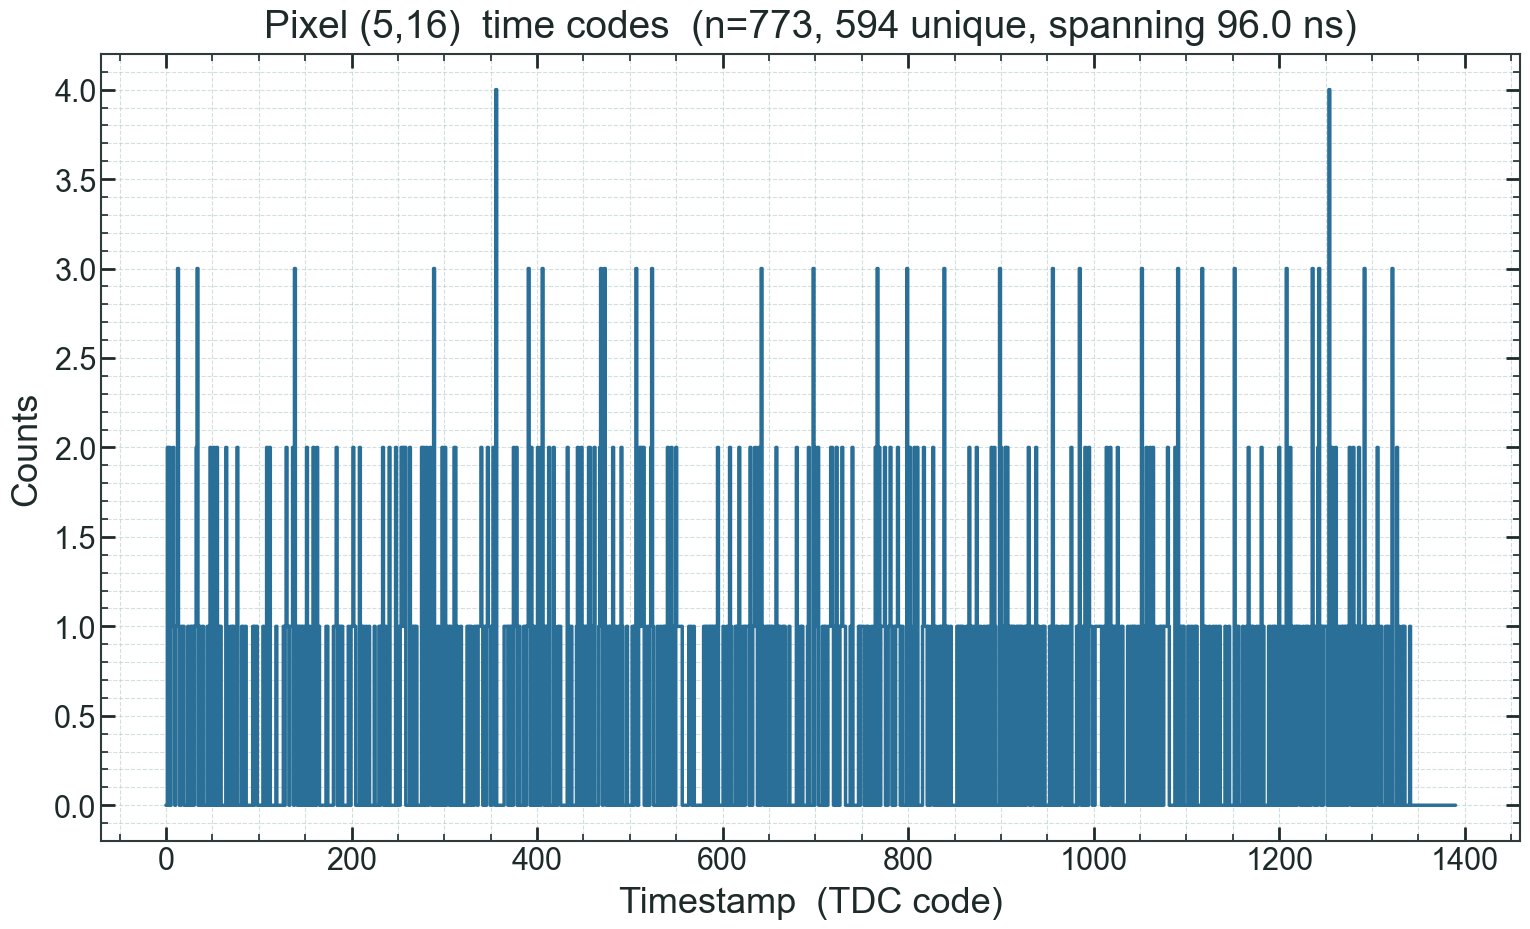

In [6]:
pixel = (5, 16)
hist = data_quality.plot_time_codes(path, pixel=pixel, tag=tag)

used = np.nonzero(hist)[0]
print(f"{hist.sum()} timestamps, {used.size} unique codes, last code {used[-1]}")

How to read the result:

| clock | healthy: codes spread up to about | full scale |
|---|---|---|
| 50 MHz | 279 | 20 ns |
| 10 MHz | 1397 | 100 ns |
| 2 MHz | 6985 | 500 ns |

A broken run collapses onto a handful of codes: a few unique values out of
thousands of timestamps, often one code repeated in every frame. If you see
that, stop here; nothing downstream will be meaningful.

## 4. Check a few more pixels

Replotting costs a load, not a re-read of the raw data, so checking a corner
and an edge pixel too is cheap:


> > > Plot is saved as 2026.10.30_ort_time_codes_0_0.png in D:\Kelpie\2026.10.30\results\data_quality < < <

> > > Plot is saved as 2026.10.30_ort_time_codes_16_16.png in D:\Kelpie\2026.10.30\results\data_quality < < <

> > > Plot is saved as 2026.10.30_ort_time_codes_31_31.png in D:\Kelpie\2026.10.30\results\data_quality < < <

> > > Plot is saved as 2026.10.30_ort_time_codes_5_20.png in D:\Kelpie\2026.10.30\results\data_quality < < <


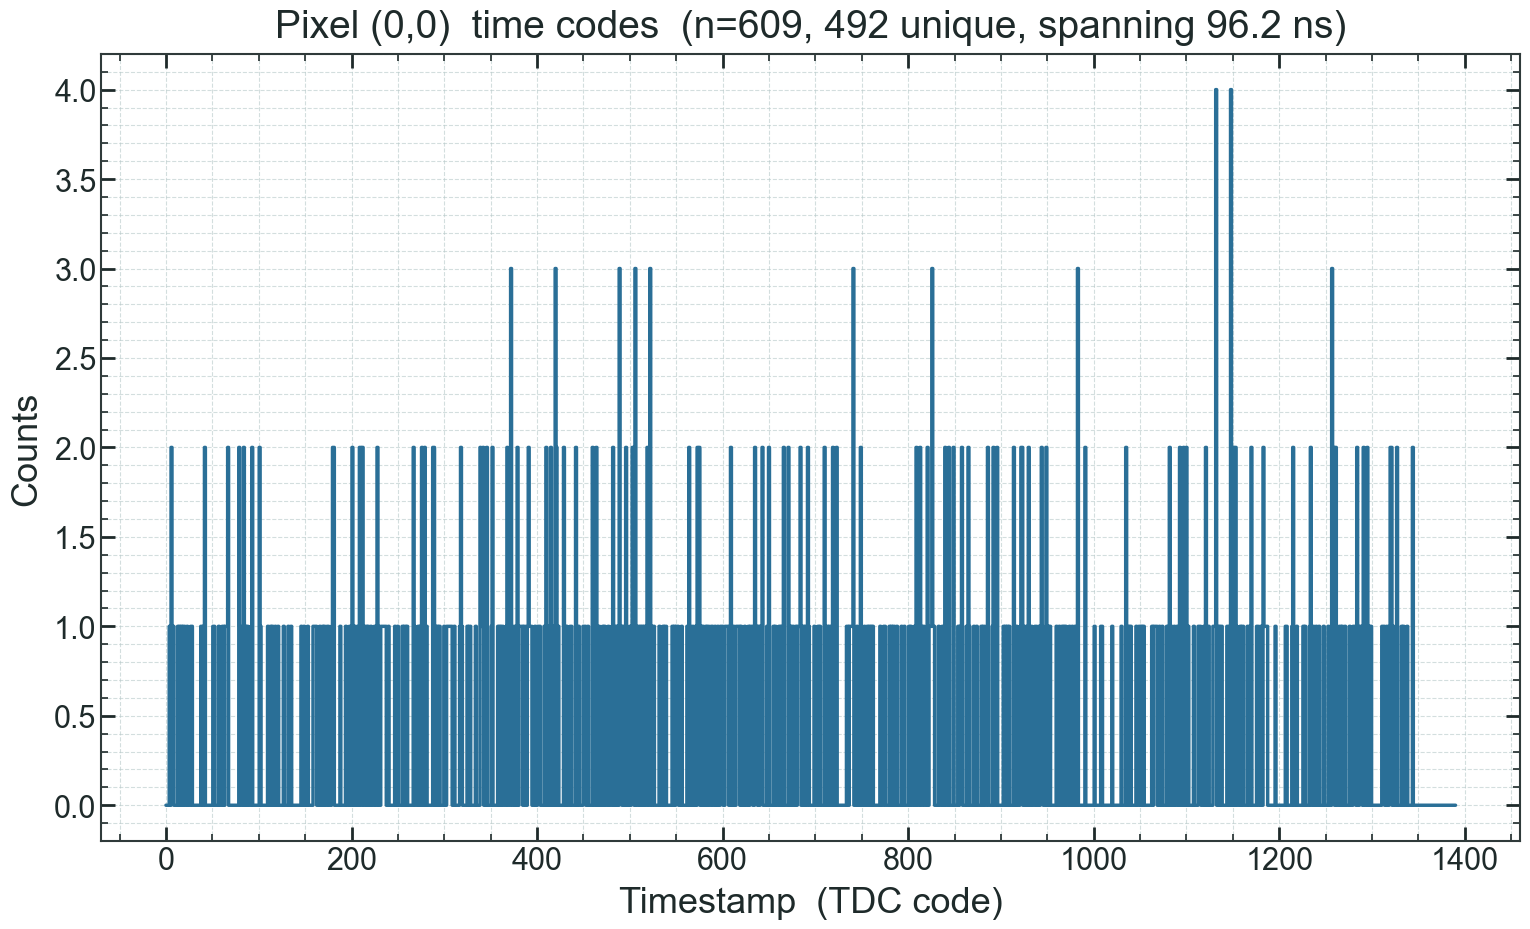

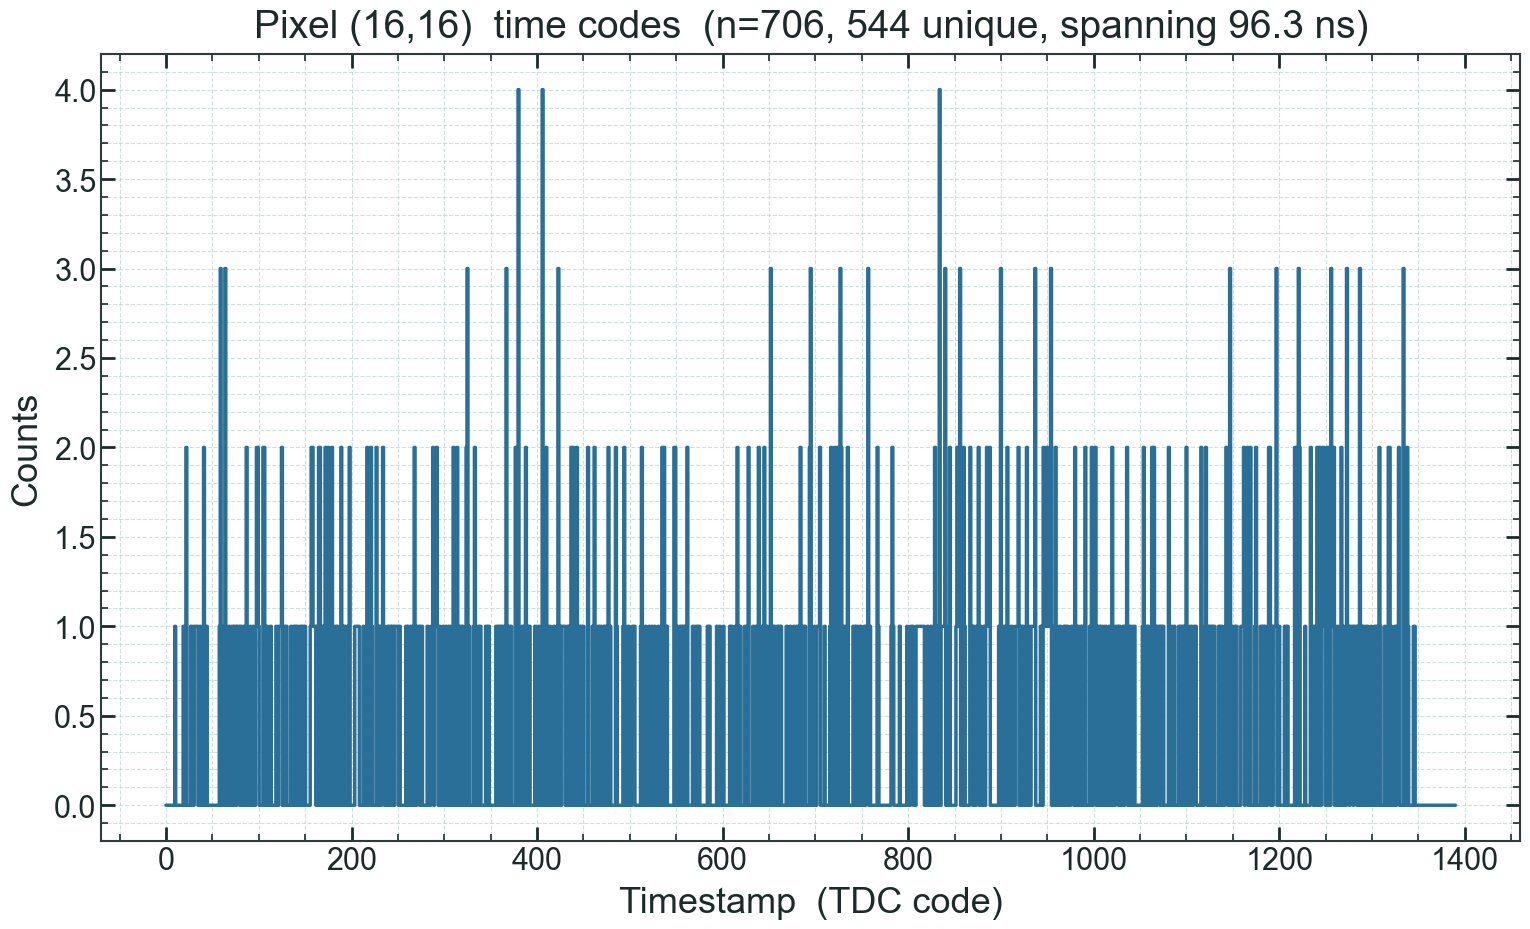

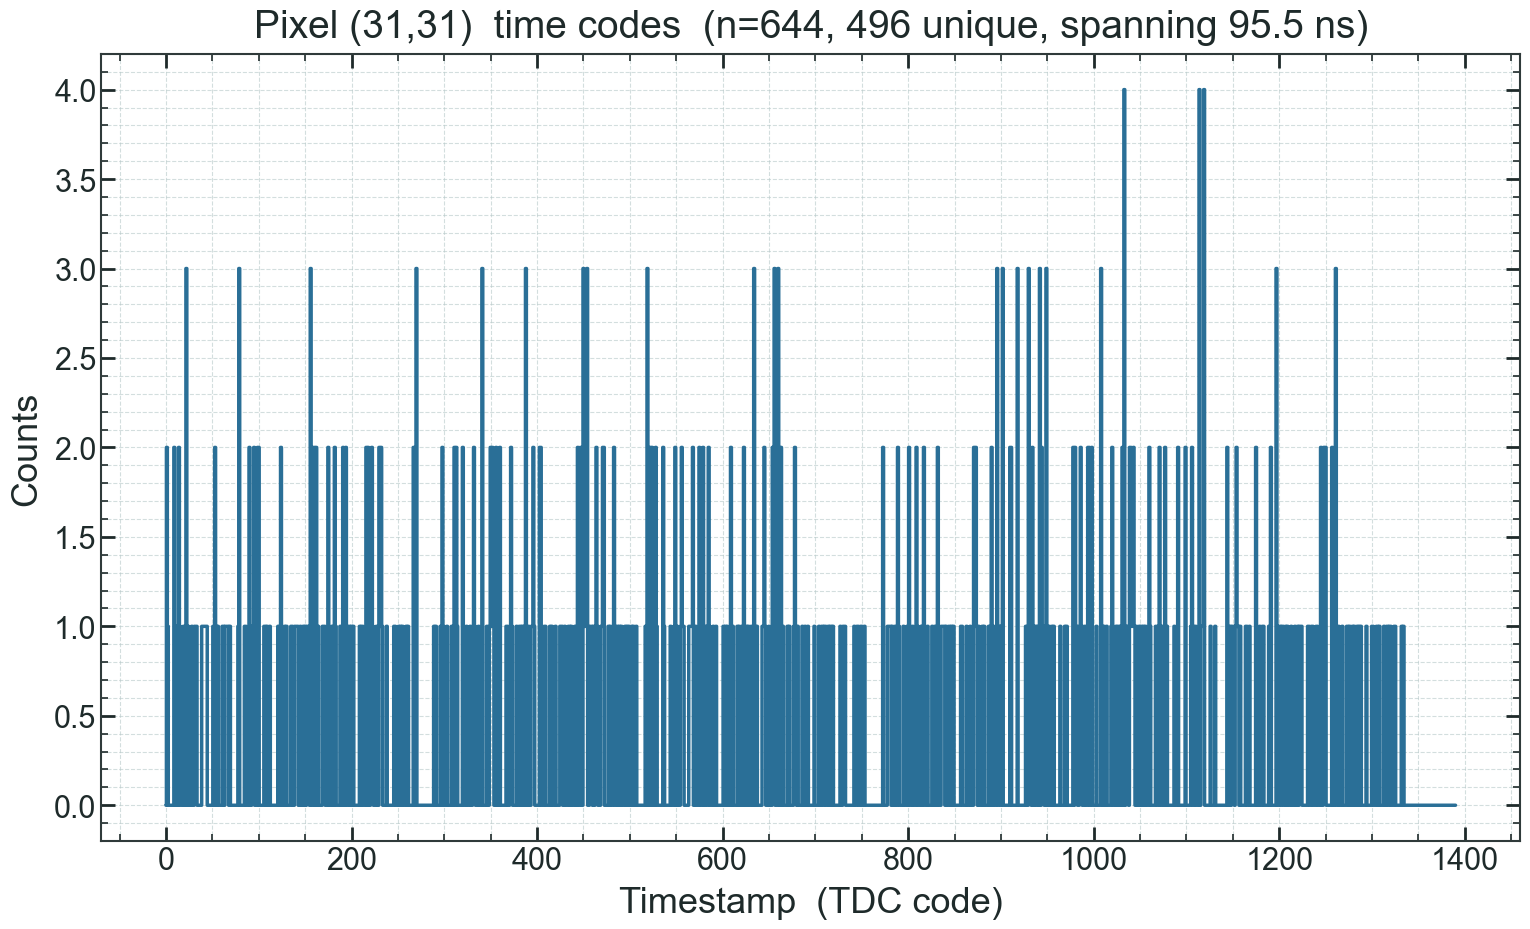

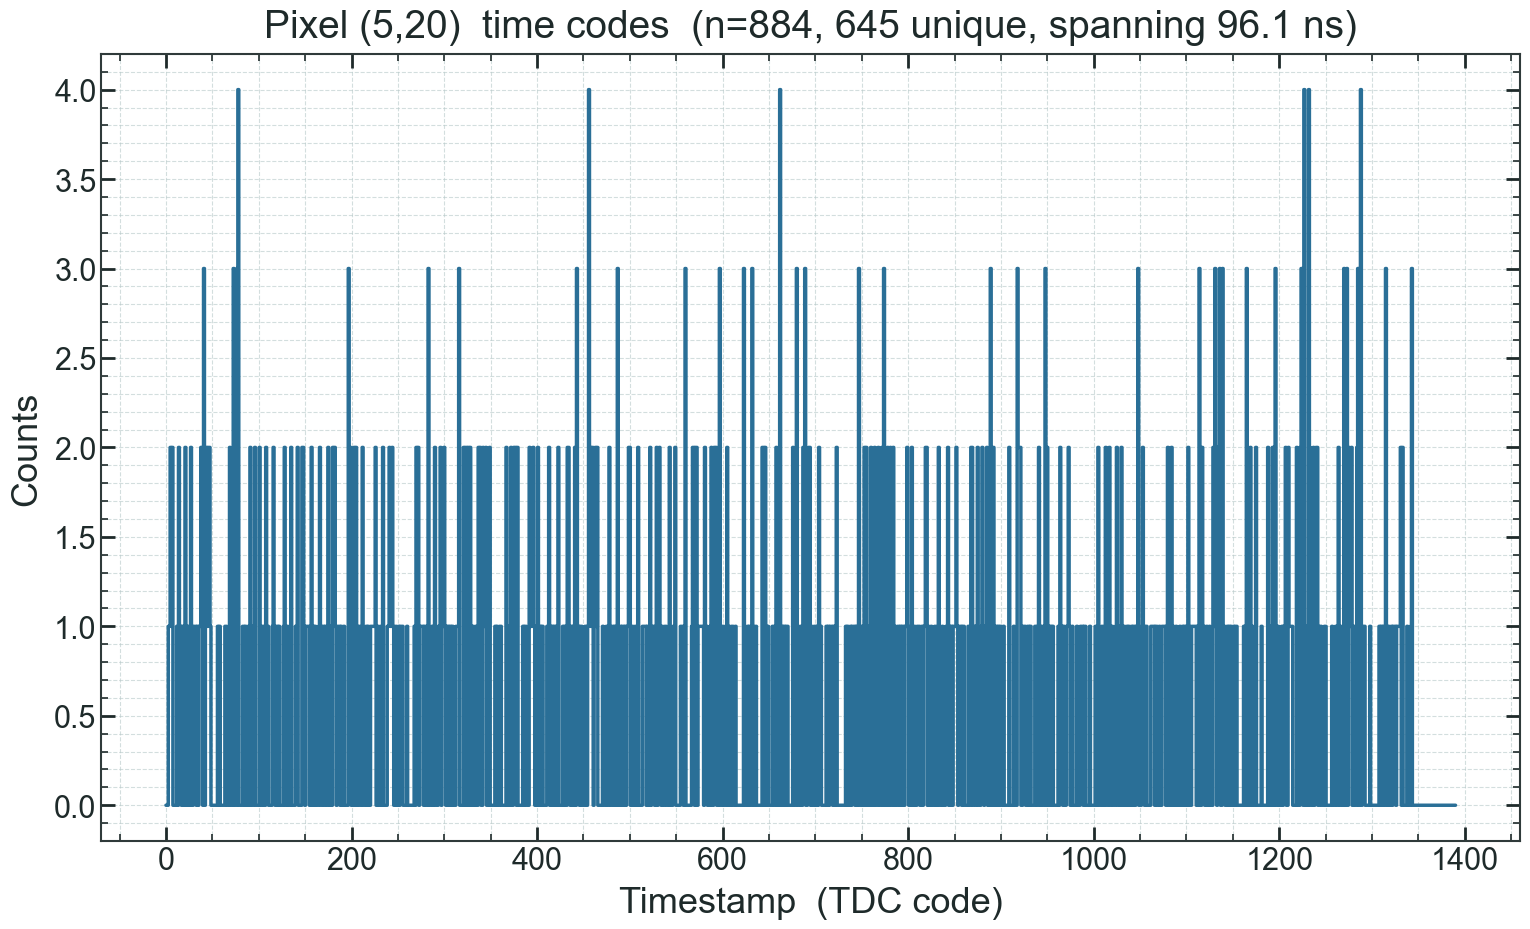

In [4]:
for pixel in [(0, 0), (16, 16), (31, 31), (5, 20)]:
    data_quality.plot_time_codes(path, pixel=pixel, tag=tag)

## 5. Check all pixels at once

The saved array covers every pixel, so you can count unique codes across the
whole sensor without plotting each pixel:

In [5]:
from dapkel.core import store

counts, meta = store.load_map(path, kind="time_codes", tag=tag)
unique_codes = (counts > 0).sum(axis=-1)  # (32, 32)
print(
    f"unique codes per pixel: median {np.median(unique_codes):.0f}, "
    f"min {unique_codes.min()}"
)
print(
    "pixels with fewer than 50 unique codes:", np.argwhere(unique_codes < 50).tolist()
)

unique codes per pixel: median 582, min 463
pixels with fewer than 50 unique codes: []


## Next

Healthy codes: go on to [TDC calibration](02_tdc_calibration.ipynb) if the board
needs one, or straight to the [hitmap](05_hitmap.ipynb) and
[coincidences](06_coincidences.ipynb).